# TL3: Hiperparámetros

## Índice
1. Introducción
2. SGD
3. Validación
4. Validación cruzada
5. Exploración de hiperparámetros
6. Ejercicio

---


# 1. Introducción

* **Objetivo:** Introducir herramientas estándar para realizar experimentos de ajuste de hiperparámetros.
* **SGD:** Usamos `LogisticRegression` en lugar de `SGDClassifier` (con `loss=log_loss`).
* **Validación:** Mediante la popular función `train_test_split`.
* **Validación cruzada:** En K bloques o con divisiones aleatorias.
* **Exploración de hiperparámetros:** Mediante exploración exhaustiva o aleatoria en una rejilla.

# 2. SGD

* **SGD en scikit-learn:** `SGDClassifier` con `loss=log_loss` es regresión logística ajustada con SGD.
* **LogisticRegression:** Es regresión logística ajustada con otros solvers; por omisión, `solver=lbfgs` por su robustez.
* **MNIST:** Aunque cabe esperar resultados similares, usamos `LogisticRegression` en lugar de `SGDClassifier`.

In [2]:
import numpy as np
import datasets
from sklearn.decomposition import PCA

ds = datasets.load_dataset("ylecun/mnist").with_format("numpy")
X_train = ds['train'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)

K = 400
pca = PCA(n_components=K)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

/home/abigbean/D/UPV/2do/UPV/APA/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(60000, 400) (60000,) (10000, 400) (10000,)


In [3]:
from sklearn.linear_model import LogisticRegression

acc = LogisticRegression(C=0.1, max_iter=200).fit(X_train, y_train).score(X_test, y_test)
print(f"Precisión LogisticRegression: {acc:.1%}")

Precisión LogisticRegression: 92.6%


In [4]:
from sklearn.linear_model import SGDClassifier

acc = SGDClassifier(loss='log_loss').fit(X_train, y_train).score(X_test, y_test)
print(f"Precisión SGDClassifier: {acc:.1%}")

Precisión SGDClassifier: 91.8%


##  Ejercicio:
Compara `LogisticRegression` y `SGDClassifier` en Fashion-MNIST con $K = 600$ y CIFAR-10 con $K = 1000$.

### Solución

# 3. Validación

* **Validación:** Método popular y sencillo para ajustar un vector de hiperparámetros $\lambda$.
  * Dividimos los datos en un conjunto de **entrenamiento** $\mathcal{D}_{\text{train}}$ y otro de **validación o desarrollo** $\mathcal{D}_{\text{valid}}$.
  * Cada valor de $\lambda$ se evalúa con $\mathcal{D}_{\text{valid}}$ tras ajustar el modelo con $\mathcal{D}_{\text{train}}$.
  * Elegimos el $\lambda$ que proporciona mejor rendimiento en $\mathcal{D}_{\text{valid}}$.

* **El test no se usa:** $\mathcal{D}_{\text{train}}$ y $\mathcal{D}_{\text{valid}}$ se obtienen dividiendo los datos de entrenamiento, nunca los de test.
* **Si el test se usa muchas veces:** Es más validación que test y el mejor resultado obtenido es optimista.

---

### `train_test_split`: Divide arrays o matrices en subconjuntos aleatorios de train y test

* `test_size=None`: Fracción de datos a incluir en el test; `None` equivale a $0.25$ ($25\%$).
* `train_size=None`: Fracción de datos a incluir en el train; `None` equivale a escoger el complemento del test.
* `random_state=None`: Semilla para controlar el barajado previo a la división.
* `shuffle=True`: Barajar o no los datos antes de dividirlos.
* `stratify=None`: Etiquetado de los datos para producir una división estratificada (por clases).

**Ejemplo:** División aleatoria de 10 datos de 2 clases en un train con 7 y un test con 3.

In [5]:
import numpy as np
from sklearn.model_selection import train_test_split

X = np.arange(10)
y = np.hstack((np.repeat(0, 5), np.repeat(1, 5)))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=23)

np.vstack((X_train, y_train)), np.vstack((X_test, y_test))

(array([[9, 4, 7, 1, 0, 6, 3],
        [1, 0, 1, 0, 0, 1, 0]]),
 array([[5, 8, 2],
        [1, 1, 0]]))

* **MNIST:** Ajuste del hiperparámetro `C` de `LogisticRegression`; positivo, cuanto mayor `C`, mayor desregularización.

In [6]:
import numpy as np
import datasets
from sklearn.decomposition import PCA

ds = datasets.load_dataset("ylecun/mnist").with_format("numpy")
X_train = ds['train'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)

K = 400
pca = PCA(n_components=K)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X_tr2, X_valid, y_tr2, y_valid = train_test_split(X_train, y_train, test_size=0.25, random_state=23)

Cs = np.array([.01, .02, .05, .1, .2, .5, 1, 2, 5, 10])
acc = np.zeros_like(Cs, dtype=float)

for i, C in enumerate(Cs):
    acc[i] = LogisticRegression(C=C, max_iter=200).fit(X_tr2, y_tr2).score(X_valid, y_valid)

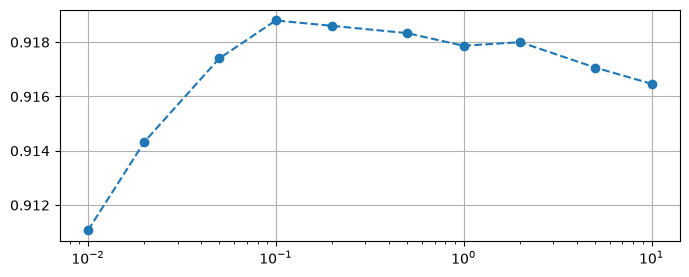

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 3))
plt.grid()
plt.semilogx(Cs, acc, 'o--')
plt.show()

* **Evaluación:** Evaluación en test tras entrenar con todo el train y el mejor $C$ hallado.

In [9]:
C_star = 0.1
acc = LogisticRegression(C=C_star, max_iter=200).fit(X_train, y_train).score(X_test, y_test)
print(f"Precisión LogisticRegression con C = {C_star}: {acc:.1%}")

Precisión LogisticRegression con C = 0.1: 92.6%


# 4. Validación cruzada

* **K-fold cross validation (KCV):** Versión refinada de validación que aprovecha todos los datos para validar.
  * Dividimos los datos en $K$ bloques, $\mathcal{D}_1, \ldots, \mathcal{D}_K$.
  * Cada valor de $\lambda$ se evalúa con cada bloque $\mathcal{D}_k$ tras ajustar el modelo con el resto de bloques, $\mathcal{D}_{-k}$.
  * Elegimos el $\lambda$ que proporciona mejor rendimiento promedio.

---

### `KFold`: Validador cruzado en K bloques

* `n_splits=5`: $K$.
* `shuffle=False`: Barajar o no los datos antes de particionarlos en $K$ bloques.
* `random_state=None`: Semilla para controlar el barajado previo a la partición; solo con `shuffle=True`.

**Ejemplo:** Particiones de 10 datos de 2 clases con 5 bloques.

In [10]:
import numpy as np
from sklearn.model_selection import KFold

X = np.arange(10)
kf = KFold(n_splits=5, shuffle=True, random_state=23)
for i, (X_train_ind, X_valid_ind) in enumerate(kf.split(X)):
    print(f"Split {i}: {X_train_ind} {X_valid_ind}")

Split 0: [0 1 2 3 4 6 7 9] [5 8]
Split 1: [0 1 3 4 5 6 7 8] [2 9]
Split 2: [0 1 2 3 5 6 8 9] [4 7]
Split 3: [2 3 4 5 6 7 8 9] [0 1]
Split 4: [0 1 2 4 5 7 8 9] [3 6]


* `cross_val_score`: Función auxiliar para simplificar la evaluación del rendimiento con validación cruzada.

* **MNIST:** Ajuste del hiperparámetro `C` de `LogisticRegression`; positivo, cuanto mayor `C`, mayor desregularización.

In [11]:
import numpy as np
import datasets
from sklearn.decomposition import PCA

ds = datasets.load_dataset("ylecun/mnist").with_format("numpy")
X_train = ds['train'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)

K = 400
pca = PCA(n_components=K)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

Tiempo (hh:mm:ss): 00:06:41


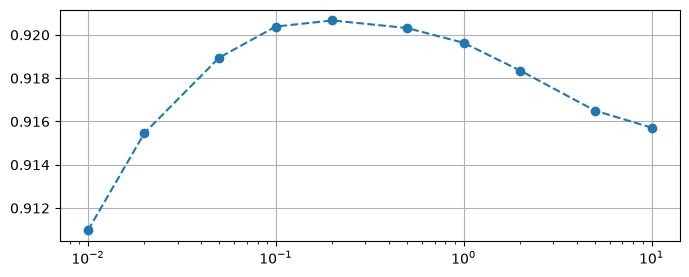

In [12]:
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
import time

start = time.time()
Cs = np.array([.01, .02, .05, .1, .2, .5, 1, 2, 5, 10])
acc = np.zeros_like(Cs)

for i, C in enumerate(Cs):
    acc[i] = cross_val_score(LogisticRegression(C=C, max_iter=200), X_train, y_train, cv=4).mean()

print('Tiempo (hh:mm:ss):', time.strftime('%H:%M:%S', time.gmtime(time.time() - start)))

plt.figure(figsize=(8, 3))
plt.grid()
plt.semilogx(Cs, acc, 'o--')
plt.show()

In [13]:
C_star = 0.2
acc = LogisticRegression(C=C_star, max_iter=200).fit(X_train, y_train).score(X_test, y_test)
print(f"Precisión LogisticRegression con C = {C_star}: {acc:.1%}")

Precisión LogisticRegression con C = 0.2: 92.6%


* **Validación cruzada con divisiones aleatorias:** Estrategia popular, más flexible que KCV.

---

### `ShuffleSplit`: Validador cruzado mediante divisiones aleatorias

* `n_splits=10`: Número de divisiones aleatorias[cite: 6].
* `test_size=None`: Fracción de test; `None` para escoger el complemento del train; `0.1` si `train_size=None`[cite: 6].
* `train_size=None`: Fracción de train; `None` para escoger el complemento del test[cite: 6].
* `random_state=None`: Semilla para controlar las divisiones aleatorias[cite: 6].

* **MNIST:** Ajuste del hiperparámetro `C` de `LogisticRegression`[cite: 6].

Tiempo (hh:mm:ss): 00:06:21


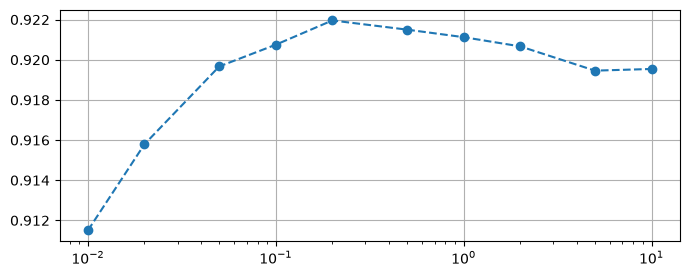

In [14]:
import matplotlib.pyplot as plt
from sklearn.model_selection import ShuffleSplit, cross_val_score
from sklearn.linear_model import LogisticRegression
import time

start = time.time()
Cs = np.array([.01, .02, .05, .1, .2, .5, 1, 2, 5, 10])
acc = np.zeros_like(Cs)
splitter = ShuffleSplit(n_splits=4, test_size=0.1, random_state=23)

for i, C in enumerate(Cs):
    acc[i] = cross_val_score(LogisticRegression(C=C, max_iter=200), X_train, y_train, cv=splitter).mean()

print('Tiempo (hh:mm:ss):', time.strftime('%H:%M:%S', time.gmtime(time.time() - start)))

plt.figure(figsize=(8, 3))
plt.grid()
plt.semilogx(Cs, acc, 'o--')
plt.show()

# 5. Exploración de hiperparámetros

* **GridSearchCV:** Búsqueda exhaustiva en una rejilla de valores[cite: 7].
* **RandomizedSearchCV:** Búsqueda en una rejilla de valores de `n_iter=10` valores escogidos aleatoriamente[cite: 7].

* **MNIST:** Exploración exhaustiva de 30 valores vs aleatoria de 10[cite: 7].

In [15]:
import numpy as np
import datasets
from sklearn.decomposition import PCA

ds = datasets.load_dataset("ylecun/mnist").with_format("numpy")
X_train = ds['train'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)

K = 400
pca = PCA(n_components=K)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

In [16]:
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import ShuffleSplit, GridSearchCV
from sklearn.linear_model import LogisticRegression
import time

start = time.time()
clf = LogisticRegression()
G = {"C": [.01, .02, .05, .1, .2, .5, 1, 2, 5, 10], "max_iter": [100, 200, 300]}
splitter = ShuffleSplit(n_splits=2, test_size=0.1, random_state=23)
GS = GridSearchCV(clf, G, scoring='accuracy', n_jobs=-1, cv=splitter, pre_dispatch=8)
acc = GS.fit(X_train, y_train).score(X_test, y_test)

print(f"Precisión: {acc:.1%} con {GS.best_params_}")
print('Tiempo (hh:mm:ss):', time.strftime('%H:%M:%S', time.gmtime(time.time() - start)))

Precisión: 92.6% con {'C': 0.1, 'max_iter': 100}
Tiempo (hh:mm:ss): 00:01:06


## 4. Ejercicio

* **Ejercicio:** Reproduce el experimento de exploración de hiperparámetros con MNIST en Fashion-MNIST con $K = 600$ y CIFAR-10 con $K = 1000$[cite: 8].